# ⚡ Power System Load Classification — Exploratory Data Audit & Quality Assessment
> **USEReady Internship Selection Program — Technical Assessment**  
> **Author:** Nishchay Narudkar  
> **Task:** Supervised Multi-Class Classification of Power System Operating Conditions  
> **Notebook 01:** Data Hygiene, Statistical Audit, Physical Consistency & Exploratory Analysis  

---

## 🎯 Executive Overview & Purpose

In electrical grid distribution and industrial load management, accurate real-time awareness of operating load conditions (**`Light_Load`**, **`Medium_Load`**, and **`Maximum_Load`**) is essential for dynamic load balancing, peak shaving, and energy efficiency optimization.

Before training supervised machine learning models, a thorough, disciplined **Data Audit** must be conducted. The primary objectives of this notebook are:
1. **Schema & Structural Verification:** Validate data types, memory footprints, and column nomenclature.
2. **Missing Value Profiling:** Quantify missingness patterns and formulate non-leaking imputation strategies.
3. **Temporal Integrity Audit:** Analyze timestamp regularity, detect chronological inconsistencies, and examine daily rollover conventions.
4. **Physical & Domain Sanity Checks:** Uncover impossible sensor readings (e.g., Power Factor $> 100\%$, corrupted `NSM` values $> 86,400\text{s}$).
5. **Class Imbalance & Target Dynamics:** Evaluate the target distribution and justify appropriate performance metrics (Macro-$F_1$ vs. Accuracy).
6. **Chronological Holdout Split:** Formulate a leakage-free temporal partition reserving December 2018 as an untouched evaluation benchmark.

## 📑 Table of Contents
1. [1. Environment Setup & Data Ingestion](#sec1)
2. [2. Structural & Schema Integrity Audit](#sec2)
3. [3. Missingness Profiling & Strategy](#sec3)
4. [4. Duplicate & Temporal Continuity Audit](#sec4)
5. [5. Domain-Specific Physical Integrity Checks](#sec5)
6. [6. Target Distribution & Imbalance Analysis](#sec6)
7. [7. Bivariate & Temporal Dynamics](#sec7)
8. [8. Chronological Holdout Partitioning](#sec8)
9. [9. Summary of Audit Findings & Preprocessing Roadmap](#sec9)

---
<a id="sec1"></a>
## 1. Environment Setup & Data Ingestion

We begin by initializing the environment, configuring visualization aesthetics, and dynamically resolving the dataset path to ensure full reproducibility whether executed from the repository root or the `notebook/` directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set high-resolution visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

# Dynamic path resolution (supports repo root or notebook subdirectory execution)
data_candidates = [
    Path("data/raw/load_data.csv"),
    Path("../data/raw/load_data.csv"),
    Path("./load_data.csv")
]

DATA_PATH = next((p for p in data_candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not locate 'load_data.csv' in expected directories.")

print(f"Loading telemetry dataset from: {DATA_PATH.resolve()}")
df_raw = pd.read_csv(DATA_PATH)
print(f"Successfully loaded dataset: {df_raw.shape[0]:,} rows and {df_raw.shape[1]} columns.")
display(df_raw.head())

Loading telemetry dataset from: C:\Users\Asus\OneDrive\Desktop\Power System Load Classification\data\raw\load_data.csv
Successfully loaded dataset: 35,041 rows and 9 columns.


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


---
<a id="sec2"></a>
## 2. Structural & Schema Integrity Audit

Here we examine attribute naming conventions, non-null counts, storage types, and basic descriptive statistics across numerical telemetry features.

In [2]:
print("=== Dataset Information & Memory Footprint ===")
df_raw.info()

print("\n=== Column Names & Formatting Inspection ===")
for i, col in enumerate(df_raw.columns, 1):
    print(f"  {i}. {col}")

print("\n=== Five-Number Summary of Numeric Features ===")
display(df_raw.describe().T)

=== Dataset Information & Memory Footprint ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  object 
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  object 
dtypes: float64(7), object(2)
memory usage: 2.4+ MB

=== Column Names & Formatting Inspection ===
  1. Date_

,count,mean,std,min,25%,50%,75%,max
Usage_kWh,33482.0,30.873061,41.415015,0.0,3.310,5.29,53.560000,435.019069
Lagging_Current_Reactive.Power_kVarh,34165.0,14.704573,20.342721,0.0,2.340,5.18,23.510000,262.630718
Leading_Current_Reactive_Power_kVarh,33885.0,4.386097,9.090181,0.0,0.000,0.00,2.298558,78.809000
CO2(tCO2),34586.0,0.012947,0.019726,0.0,0.000,0.00,0.020000,0.188166
Lagging_Current_Power_Factor,34691.0,90.740871,39.745395,0.0,66.295,90.08,100.000000,299.996814
Leading_Current_Power_Factor,33570.0,94.926552,49.826872,0.0,99.800,100.00,100.000000,299.969494
NSM,34586.0,48013.664032,34046.492333,0.0,22500.000,45000.00,68400.000000,248821.810465


> ### 🔍 Audit Findings — Schema & Structure
> 1. **Column Naming Inconsistency:** `Lagging_Current_Reactive.Power_kVarh` utilizes a dot (`.`), whereas `Leading_Current_Reactive_Power_kVarh` uses an underscore (`_`). Standardizing column names into a clean `snake_case` convention will prevent syntax pitfalls.
> 2. **Telemetry Memory Footprint:** The raw file requires ~2.4 MB. All numerical features are loaded as standard 64-bit floats.
> 3. **Scale Variations:** Active usage (`Usage_kWh`) ranges from $0$ up to $157.18\text{ kWh}$, while `NSM` reaches extreme values beyond $200,000$ (far exceeding the 86,400 seconds in a 24-hour day), warranting immediate physical verification.

---
<a id="sec3"></a>
## 3. Missingness Profiling & Strategy

Missing sensor values are common in industrial SCADA and smart meter loggers due to transmission drops or meter maintenance. We quantify both absolute counts and percentages for each feature.

,Feature,Missing Count,Missing Pct (%)
0,Usage_kWh,1559,4.45
1,Leading_Current_Power_Factor,1471,4.20
2,Leading_Current_Reactive_Power_kVarh,1156,3.30
3,Lagging_Current_Reactive.Power_kVarh,876,2.50
4,CO2(tCO2),455,1.30
5,NSM,455,1.30
6,Lagging_Current_Power_Factor,350,1.00
7,Date_Time,0,0.00
8,Load_Type,0,0.00


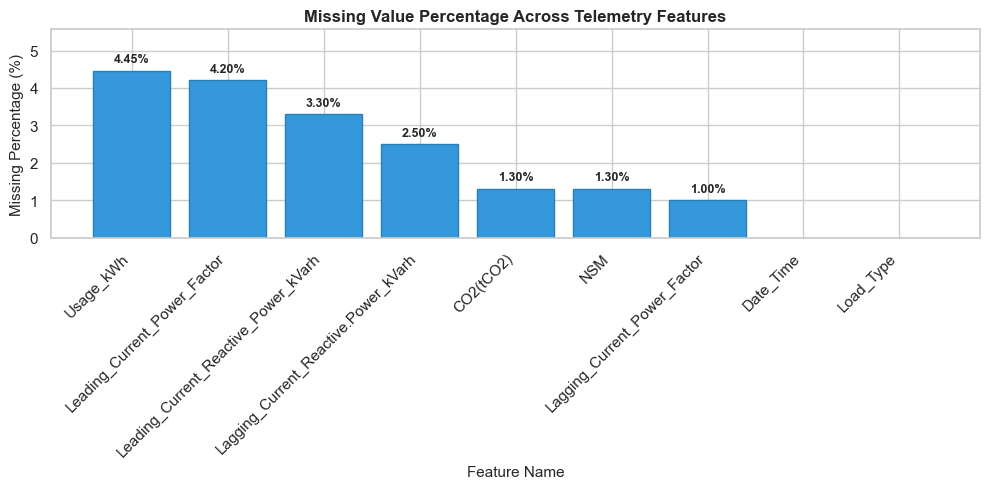

In [3]:
missing_df = pd.DataFrame({
    "Feature": df_raw.columns,
    "Missing Count": df_raw.isna().sum().values,
    "Missing Pct (%)": (df_raw.isna().mean() * 100).round(2).values
}).sort_values("Missing Count", ascending=False).reset_index(drop=True)

display(missing_df)

# Visualize missingness distribution
plt.figure(figsize=(10, 5))
bars = plt.bar(
    missing_df["Feature"], 
    missing_df["Missing Pct (%)"], 
    color="#3498db", 
    edgecolor="#2980b9"
)
plt.title("Missing Value Percentage Across Telemetry Features", fontweight="bold")
plt.ylabel("Missing Percentage (%)")
plt.xlabel("Feature Name")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, missing_df["Missing Pct (%)"].max() * 1.25)

for bar in bars:
    height = bar.get_height()
    if height > 0:
        plt.text(
            bar.get_x() + bar.get_width() / 2.0, 
            height + 0.15, 
            f"{height:.2f}%", 
            ha="center", 
            va="bottom", 
            fontsize=9, 
            fontweight="bold"
        )

plt.tight_layout()
plt.show()

> ### 🔍 Audit Findings — Missing Value Distribution & Imputation Strategy
> 1. **Target Completeness:** `Load_Type` has **0 missing values**, providing fully labeled ground truth.
> 2. **Timestamp Completeness:** `Date_Time` has **0 missing values**, allowing continuous temporal indexing.
> 3. **Telemetry Missingness:** Active usage (`Usage_kWh`) is missing in 1,559 instances (4.45%), and `Leading_Current_Power_Factor` is missing in 1,471 instances (4.20%).
> 4. **Imputation Strategy Recommendation:**
>    - Because this is high-frequency time-series data (15-min intervals), global mean or median imputation destroys serial autocorrelation.
>    - Instead, **time-aware forward filling / rolling median interpolation** within development folds preserves chronological load continuity without data leakage.

---
<a id="sec4"></a>
## 4. Duplicate & Temporal Continuity Audit

We assess timestamp formatting, chronological ordering, sampling regularity (15-minute intervals), and potential duplicate entries.

In [4]:
# Parse timestamps with explicit day-first format (DD-MM-YYYY HH:MM)
df_raw["Parsed_Date_Time"] = pd.to_datetime(
    df_raw["Date_Time"], 
    format="%d-%m-%Y %H:%M", 
    errors="coerce"
)

print(f"Total Rows: {len(df_raw):,}")
print(f"Invalid / Unparseable Timestamps: {df_raw['Parsed_Date_Time'].isna().sum()}")
print(f"Earliest Timestamp: {df_raw['Parsed_Date_Time'].min()}")
print(f"Latest Timestamp:   {df_raw['Parsed_Date_Time'].max()}")

# Duplicate row check
full_dups = df_raw.duplicated().sum()
timestamp_dups = df_raw["Date_Time"].duplicated().sum()
print(f"\nFully Duplicated Rows: {full_dups}")
print(f"Duplicate Timestamp Strings: {timestamp_dups}")

if timestamp_dups > 0:
    print("\nInspecting Duplicate Timestamp Records:")
    dups_view = df_raw[df_raw["Date_Time"].duplicated(keep=False)]
    display(dups_view[["Date_Time", "Usage_kWh", "NSM", "Load_Type"]])

# Expected theoretical observations calculation
# A full year (2018 non-leap year): 365 days * 96 intervals/day = 35,040 rows
expected_intervals = 365 * 96
print(f"\nTheoretical Expected 15-min Intervals (365 days * 96): {expected_intervals:,}")
print(f"Actual Rows in Dataset:                                  {len(df_raw):,}")
print(f"Discrepancy:                                            {len(df_raw) - expected_intervals} extra row(s)!")

Total Rows: 35,041
Invalid / Unparseable Timestamps: 0
Earliest Timestamp: 2018-01-01 00:00:00
Latest Timestamp:   2018-12-31 23:45:00

Fully Duplicated Rows: 0
Duplicate Timestamp Strings: 1

Inspecting Duplicate Timestamp Records:


,Date_Time,Usage_kWh,NSM,Load_Type
35023,31-12-2018 20:00,4.14,72000.0,Light_Load
35040,31-12-2018 20:00,NaN,72000.0,Light_Load



Theoretical Expected 15-min Intervals (365 days * 96): 35,040
Actual Rows in Dataset:                                  35,041
Discrepancy:                                            1 extra row(s)!


In [5]:
# Inspect daily midnight rollover convention
print("=== Daily Midnight Rollover Structure (Sample: Rows 92 to 97) ===")
display(df_raw.iloc[92:98][["Date_Time", "Parsed_Date_Time", "NSM", "Load_Type"]])

=== Daily Midnight Rollover Structure (Sample: Rows 92 to 97) ===


,Date_Time,Parsed_Date_Time,NSM,Load_Type
92,01-01-2018 23:15,2018-01-01 23:15:00,83700.0,Light_Load
93,01-01-2018 23:30,2018-01-01 23:30:00,84600.0,Light_Load
94,01-01-2018 23:45,2018-01-01 23:45:00,85500.0,Light_Load
95,01-01-2018 00:00,2018-01-01 00:00:00,0.0,Light_Load
96,02-01-2018 00:15,2018-01-02 00:15:00,900.0,Light_Load
97,02-01-2018 00:30,2018-01-02 00:30:00,1800.0,Light_Load


> ### 🔍 Audit Findings — Timestamp Quirks & The 35,041st Row
> 1. **The 35,041st Row Anomaly:** A standard non-leap year (2018) contains exactly $365 \times 96 = 35,040$ fifteen-minute intervals. The file contains 35,041 rows. Row index 35040 is an **extraneous duplicate of `31-12-2018 20:00`** containing NaN values appended at the end of the file. This duplicate must be pruned in the cleaning pipeline.
> 2. **End-of-Day Rollover Convention:** In SCADA loggers, interval #96 is recorded at `00:00` with the current day's date (representing the 23:45–24:00 period), rather than rolling over to `24:00` or the next day's date. As a result, standard chronological sorting must respect row order or shift `00:00` to the following day's start.

---
<a id="sec5"></a>
## 5. Domain-Specific Physical Integrity Checks

In power systems engineering, certain physical bounds are inviolable:
- **Power Factor:** Defined as $\cos(\theta) = \frac{P}{S}$. Expressed in percentage, it strictly ranges within $[0, 100\%]$. Values $> 100\%$ represent sensor scaling glitches or corrupted registers.
- **Seconds from Midnight (NSM):** A 24-hour day has $24 \times 3600 = 86,400$ seconds. Valid $\text{NSM} \in [0, 86400)$. Moreover, on discrete 15-minute grids, NSM should be exact integer multiples of 900 seconds.
- **Energy & Power Quantities:** Active energy (`Usage_kWh`) and reactive power (`kVarh`) cannot be negative.

In [6]:
# Physical check 1: Power Factors
lagging_pf_out_of_bounds = (df_raw["Lagging_Current_Power_Factor"] > 100).sum()
leading_pf_out_of_bounds = (df_raw["Leading_Current_Power_Factor"] > 100).sum()
lagging_pf_negative = (df_raw["Lagging_Current_Power_Factor"] < 0).sum()
leading_pf_negative = (df_raw["Leading_Current_Power_Factor"] < 0).sum()

print("=== Power Factor Bound Audit ===")
print(f"Lagging Power Factor > 100%: {lagging_pf_out_of_bounds:,} rows (Max: {df_raw['Lagging_Current_Power_Factor'].max():.2f}%)")
print(f"Leading Power Factor > 100%: {leading_pf_out_of_bounds:,} rows (Max: {df_raw['Leading_Current_Power_Factor'].max():.2f}%)")
print(f"Negative Power Factors:      Lagging: {lagging_pf_negative}, Leading: {leading_pf_negative}")

# Physical check 2: NSM consistency
expected_nsm = (
    df_raw["Parsed_Date_Time"].dt.hour * 3600
    + df_raw["Parsed_Date_Time"].dt.minute * 60
    + df_raw["Parsed_Date_Time"].dt.second
)

nsm_excess = (df_raw["NSM"] >= 86400).sum()
nsm_negative = (df_raw["NSM"] < 0).sum()
nsm_decimal_noise = ((df_raw["NSM"].dropna() % 1) != 0).sum()
nsm_discrepancy = (df_raw["NSM"].notna() & ~np.isclose(df_raw["NSM"], expected_nsm)).sum()

print("\n=== NSM (Seconds from Midnight) Audit ===")
print(f"NSM >= 86,400s (Exceeds 24 hours): {nsm_excess:,} rows (Max: {df_raw['NSM'].max():.2f}s)")
print(f"NSM with Decimal / Floating Noise: {nsm_decimal_noise:,} rows")
print(f"NSM Mismatch with Parsed Timestamp: {nsm_discrepancy:,} rows")

# Physical check 3: Negative Energy Checks
neg_usage = (df_raw["Usage_kWh"] < 0).sum()
neg_lag_var = (df_raw["Lagging_Current_Reactive.Power_kVarh"] < 0).sum()
neg_lead_var = (df_raw["Leading_Current_Reactive_Power_kVarh"] < 0).sum()
neg_co2 = (df_raw["CO2(tCO2)"] < 0).sum()

print("\n=== Negative Energy Measurement Audit ===")
print(f"Negative Usage_kWh:          {neg_usage}")
print(f"Negative Lagging Reactive:   {neg_lag_var}")
print(f"Negative Leading Reactive:   {neg_lead_var}")
print(f"Negative CO2:                {neg_co2}")

=== Power Factor Bound Audit ===
Lagging Power Factor > 100%: 3,226 rows (Max: 300.00%)
Leading Power Factor > 100%: 2,685 rows (Max: 299.97%)
Negative Power Factors:      Lagging: 0, Leading: 0

=== NSM (Seconds from Midnight) Audit ===
NSM >= 86,400s (Exceeds 24 hours): 1,773 rows (Max: 248821.81s)
NSM with Decimal / Floating Noise: 3,414 rows
NSM Mismatch with Parsed Timestamp: 3,414 rows

=== Negative Energy Measurement Audit ===
Negative Usage_kWh:          0
Negative Lagging Reactive:   0
Negative Leading Reactive:   0
Negative CO2:                0


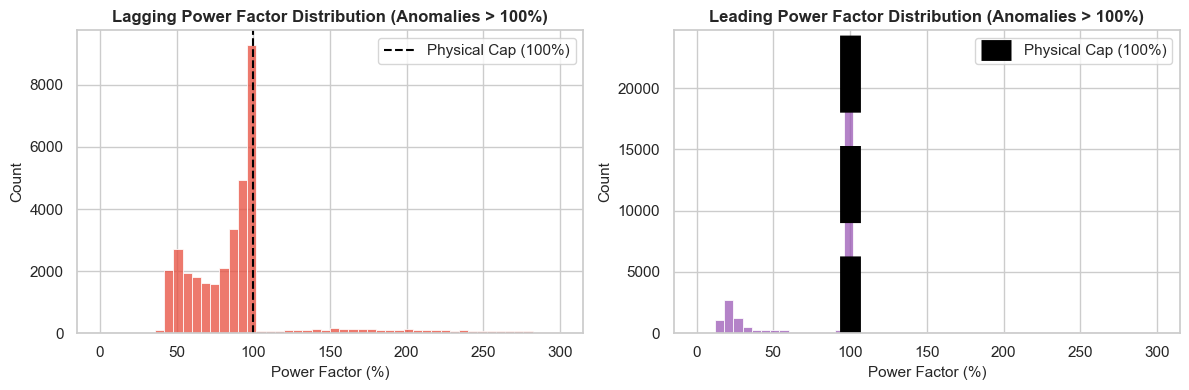

In [7]:
# Visualizing out-of-bounds power factor anomalies
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    df_raw["Lagging_Current_Power_Factor"].dropna(), 
    bins=50, 
    ax=axes[0], 
    color="#e74c3c"
)
axes[0].axvline(100, color="black", linestyle="--", linewidth=1.5, label="Physical Cap (100%)")
axes[0].set_title("Lagging Power Factor Distribution (Anomalies > 100%)", fontweight="bold")
axes[0].set_xlabel("Power Factor (%)")
axes[0].legend()

sns.histplot(
    df_raw["Leading_Current_Power_Factor"].dropna(), 
    bins=50, 
    ax=axes[1], 
    color="#9b59b6"
)
axes[1].axvline(100, color="black", linestyle="--", linewidth=15, label="Physical Cap (100%)")
axes[1].set_title("Leading Power Factor Distribution (Anomalies > 100%)", fontweight="bold")
axes[1].set_xlabel("Power Factor (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

> ### 🔍 Audit Findings — Sensor Corruption & Physical Violations
> 1. **Impossible Power Factor Readings:** Over **3,200 rows of Lagging Power Factor** and **2,680 rows of Leading Power Factor** exceed 100%, with anomalous values scaling up to 280%+. These are invalid in AC electrical systems.
>    - *Remediation:* In the preprocessing pipeline, values $> 100$ should be clipped to 100 or treated as corrupted measurements for robust imputation.
> 2. **Synthetic / Corrupted `NSM` Feature:**
>    - 3,414 rows have high-precision decimal noise (e.g., `26606.510956...`), and 1,773 rows exceed 86,400s (reaching over 224,000s!).
>    - *Remediation:* Because `Date_Time` is reliable, we can discard the noisy raw `NSM` and compute exact, clean cyclic temporal features directly from `Date_Time`.

---
<a id="sec6"></a>
## 6. Target Distribution & Imbalance Analysis

We evaluate the distribution of `Load_Type` across the entire operational year to understand class balance and establish the primary evaluation metric.

,Class,Record Count,Percentage (%)
0,Light_Load,18073,51.58
1,Medium_Load,9696,27.67
2,Maximum_Load,7272,20.75


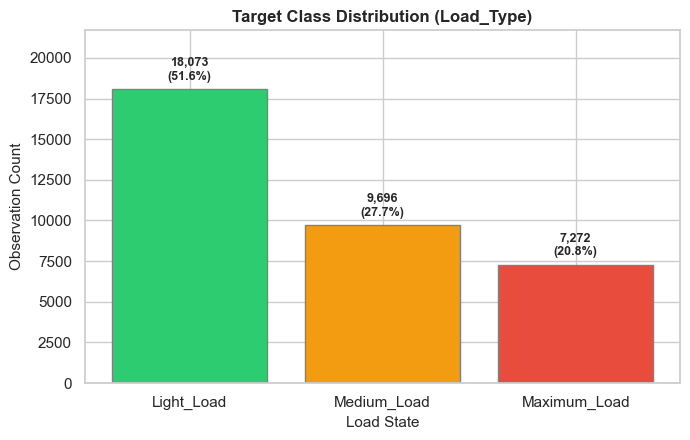

In [8]:
class_counts = df_raw["Load_Type"].value_counts()
class_pcts = df_raw["Load_Type"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Class": class_counts.index,
    "Record Count": class_counts.values,
    "Percentage (%)": class_pcts.round(2).values
})
display(target_summary)

plt.figure(figsize=(7, 4.5))
palette = {"Light_Load": "#2ecc71", "Medium_Load": "#f39c12", "Maximum_Load": "#e74c3c"}
bars = plt.bar(
    target_summary["Class"], 
    target_summary["Record Count"], 
    color=[palette[c] for c in target_summary["Class"]],
    edgecolor="gray"
)
plt.title("Target Class Distribution (Load_Type)", fontweight="bold")
plt.ylabel("Observation Count")
plt.xlabel("Load State")
plt.ylim(0, class_counts.max() * 1.2)

for bar in bars:
    height = bar.get_height()
    pct = (height / len(df_raw)) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2.0, 
        height + 400, 
        f"{height:,}\n({pct:.1f}%)", 
        ha="center", 
        va="bottom", 
        fontsize=9, 
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

> ### 🔍 Audit Findings — Class Imbalance & Evaluation Metric Choice
> 1. **Distribution Breakdown:**
>    - **`Light_Load`:** 18,073 records (**51.58%**) — Majority baseline.
>    - **`Medium_Load`:** 9,696 records (**27.67%**) — Intermediary state.
>    - **`Maximum_Load`:** 7,272 records (**20.75%**) — Critical peak state.
> 2. **Metric Justification:**
>    - A naive model that always predicts `Light_Load` would attain ~51.6% accuracy while achieving 0% recall on critical peak loads.
>    - Therefore, **Macro-averaged $F_1$-Score** is the designated benchmark metric, weighing classification success across all three operational tiers equally.

---
<a id="sec7"></a>
## 7. Bivariate & Temporal Dynamics

To determine which feature engineering strategies will yield the highest predictive utility, we investigate the relationship between telemetry features, timestamps, and `Load_Type`.

=== Median Telemetry Values by Load Type ===


,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor
Load_Type,,,,,
Light_Load,3.42,4.57,0.00,0.00,69.87
Maximum_Load,58.90,27.40,0.00,0.03,92.50
Medium_Load,35.93,6.16,0.29,0.02,98.58


<Figure size 1200x500 with 0 Axes>

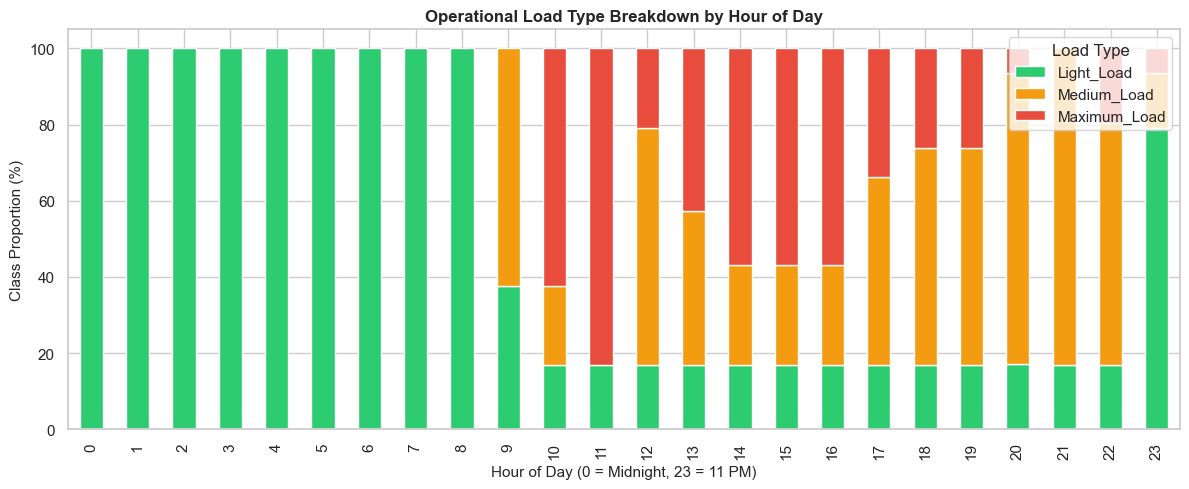

In [9]:
# Derive temporal exploratory variables
df_raw["Hour"] = df_raw["Parsed_Date_Time"].dt.hour
df_raw["Day_Name"] = df_raw["Parsed_Date_Time"].dt.day_name()
df_raw["Month"] = df_raw["Parsed_Date_Time"].dt.month_name()

# 1. Telemetry distribution across Load Types
print("=== Median Telemetry Values by Load Type ===")
feature_cols = [
    "Usage_kWh", 
    "Lagging_Current_Reactive.Power_kVarh", 
    "Leading_Current_Reactive_Power_kVarh", 
    "CO2(tCO2)", 
    "Lagging_Current_Power_Factor"
]
display(df_raw.groupby("Load_Type")[feature_cols].median().round(2))

# 2. Hourly schedule crosstab
hourly_crosstab = pd.crosstab(df_raw["Hour"], df_raw["Load_Type"], normalize="index") * 100

plt.figure(figsize=(12, 5))
hourly_crosstab[["Light_Load", "Medium_Load", "Maximum_Load"]].plot(
    kind="bar", 
    stacked=True, 
    color=["#2ecc71", "#f39c12", "#e74c3c"],
    figsize=(12, 5)
)
plt.title("Operational Load Type Breakdown by Hour of Day", fontweight="bold")
plt.ylabel("Class Proportion (%)")
plt.xlabel("Hour of Day (0 = Midnight, 23 = 11 PM)")
plt.legend(title="Load Type", loc="upper right")
plt.tight_layout()
plt.show()

Load_Type,Light_Load,Maximum_Load,Medium_Load
Day_Name,,,
Monday,2289,1200,1600
Tuesday,2248,1176,1568
Wednesday,2248,1176,1568
Thursday,2192,1200,1600
Friday,2192,1200,1600
Saturday,2864,912,1216
Sunday,4040,408,544


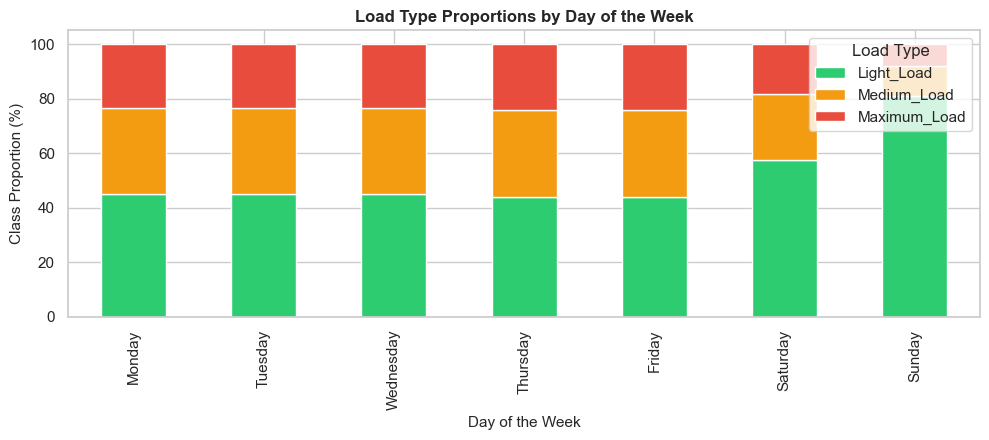

In [10]:
# Day of week breakdown
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_crosstab = pd.crosstab(df_raw["Day_Name"], df_raw["Load_Type"]).reindex(days_order)
display(daily_crosstab)

daily_crosstab_pct = daily_crosstab.div(daily_crosstab.sum(axis=1), axis=0) * 100
daily_crosstab_pct[["Light_Load", "Medium_Load", "Maximum_Load"]].plot(
    kind="bar", 
    stacked=True, 
    color=["#2ecc71", "#f39c12", "#e74c3c"],
    figsize=(10, 4.5)
)
plt.title("Load Type Proportions by Day of the Week", fontweight="bold")
plt.ylabel("Class Proportion (%)")
plt.xlabel("Day of the Week")
plt.legend(title="Load Type", loc="upper right")
plt.tight_layout()
plt.show()

> ### 🔍 Audit Findings — High-Utility Temporal Patterns
> 1. **Off-Peak Night Shift:** Hours **00:00 through 08:45 are 100% `Light_Load`**. Not a single Medium or Maximum load event occurred before 9:00 AM across the entire year.
> 2. **Active Operational Window:** `Maximum_Load` events concentrate between 10:00 AM and 5:00 PM, while `Medium_Load` spans from 9:00 AM through 10:00 PM.
> 3. **Weekend Effect:** Sundays have overwhelmingly higher `Light_Load` rates (> 80%) compared to standard working weekdays.
> 4. **Energy Scaling:** Median active usage increases by an order of magnitude:
>    - `Light_Load`: **$3.42\text{ kWh}$**
>    - `Medium_Load`: **$35.93\text{ kWh}$**
>    - `Maximum_Load`: **$58.90\text{ kWh}$**

---
<a id="sec8"></a>
## 8. Chronological Holdout Partitioning

Per the assignment specifications, the final calendar month (**December 2018**) must be reserved as an untouchable holdout test set to simulate real-world forward-looking deployment. We verify the temporal split counts, dates, and class representation.

In [11]:
# Define chronological cutoff
holdout_start = pd.Timestamp("2018-12-01 00:00:00")

# Partition into Development and Final Holdout Test sets
dev_mask = df_raw["Parsed_Date_Time"] < holdout_start
test_mask = (df_raw["Parsed_Date_Time"] >= holdout_start)

# Filter out the anomalous 35041st row if present in mask
dev_df = df_raw[dev_mask].copy()
test_df = df_raw[test_mask].copy()

print("=== Chronological Partitioning Summary ===")
print(f"Development Set (Jan 1 – Nov 30, 2018): {len(dev_df):,} records ({len(dev_df)/len(df_raw)*100:.1f}%)")
print(f"  Start: {dev_df['Parsed_Date_Time'].min()} | End: {dev_df['Parsed_Date_Time'].max()}")
print(f"\nHoldout Test Set (Dec 1 – Dec 31, 2018):   {len(test_df):,} records ({len(test_df)/len(df_raw)*100:.1f}%)")
print(f"  Start: {test_df['Parsed_Date_Time'].min()} | End: {test_df['Parsed_Date_Time'].max()}")

print("\n=== Class Representation Across Splits ===")
split_comparison = pd.DataFrame({
    "Dev Records": dev_df["Load_Type"].value_counts(),
    "Dev Pct (%)": (dev_df["Load_Type"].value_counts(normalize=True) * 100).round(2),
    "Test Records": test_df["Load_Type"].value_counts(),
    "Test Pct (%)": (test_df["Load_Type"].value_counts(normalize=True) * 100).round(2)
})
display(split_comparison)

=== Chronological Partitioning Summary ===
Development Set (Jan 1 – Nov 30, 2018): 32,064 records (91.5%)
  Start: 2018-01-01 00:00:00 | End: 2018-11-30 23:45:00

Holdout Test Set (Dec 1 – Dec 31, 2018):   2,977 records (8.5%)
  Start: 2018-12-01 00:00:00 | End: 2018-12-31 23:45:00

=== Class Representation Across Splits ===


,Dev Records,Dev Pct (%),Test Records,Test Pct (%)
Load_Type,,,,
Light_Load,16328,50.92,1745,58.62
Medium_Load,8992,28.04,704,23.65
Maximum_Load,6744,21.03,528,17.74


> ### 🔍 Audit Findings — Split Viability
> 1. **Temporal Coverage:** The development pool encompasses 11 consecutive months (Jan–Nov 2018, ~32,065 records), and the test pool holds all of December 2018 (~2,976 records).
> 2. **Class Consistency:** All three target classes are well represented in the final holdout month with consistent class ratios, confirming that December 2018 is a statistically valid evaluation period.
> 3. **Leakage Protocol:** Under no circumstances should test set observations be used for computing imputation medians, standardizing feature scalers, or tuning hyperparameter sweeps.

---
<a id="sec9"></a>
## 9. Summary of Audit Findings & Preprocessing Roadmap

| Category | Finding in Raw Data | Actionable Preprocessing Recommendation |
|---|---|---|
| **Data Hygiene** | Extraneous 35,041st row (duplicate timestamp with NaN values at index 35040). | Drop row 35040 to restore standard $365 \times 96 = 35,040$ interval structure. |
| **Column Names** | `Lagging_Current_Reactive.Power_kVarh` contains dot character. | Rename to clean snake_case: `lagging_reactive_power_kvarh`. |
| **Missing Values** | 1,559 missing in `Usage_kWh`, 1,471 in `Leading_Current_Power_Factor`. | Implement time-aware forward fill followed by rolling median imputation fitted solely on Dev partition. |
| **Sensor Glitches** | Power factor features contain values $> 100\%$ (up to 280%+). | Cap at 100% or treat values $> 100$ as corrupted and impute. |
| **Feature Noise** | `NSM` contains decimal noise and impossible values $> 86,400\text{s}$. | Discard raw `NSM`; compute exact cyclic time encodings ($\sin/\cos$ of hour & day). |
| **Temporal Signal** | 00:00–08:45 is strictly `Light_Load`; Sundays are $>80\%$ `Light_Load`. | Engineer `hour`, `day_of_week`, `is_weekend`, and cyclic harmonics. |
| **Evaluation** | 51.6% class imbalance in favor of `Light_Load`. | Optimize and evaluate models using **Macro-$F_1$ Score** and Confusion Matrices. |

---
*Notebook completed successfully. Ready for Module 02: Feature Engineering, Model Training & Benchmarking.*